# Worcester County Prosecution Analysis

**Source:** Worcester prosecution extract
**Study period:** 2017 to 2024 (filing year)

**Agreed criteria (all counties)**
- **Unit:** one row = one case = one docket number per defendant. Dockets with multiple defendants are split into one case per defendant.
- **Offense classification:** each case is classified by its most serious charge (felony over misdemeanor, then statutory class).
- **Outcome:** each case gets its most severe outcome across all charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown). Open cases are excluded from outcome metrics.
- **Missing data:** the coverage table comes first. Fields over 20% missing are marked "insufficient data" and their metrics are not reported. "Unknown" is kept as its own category.

## Setup

In [35]:
import sys, subprocess, os
repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz_style import (set_style, stacked_pct_bar, save_fig, normalize_outcome,
                       case_outcome, OUTCOME_COLORS, TEXT_SECONDARY)

set_style()

COUNTY = "worcester"
YEARS = range(2017, 2025)     # 2017 to 2024
MISSING_THRESHOLD = 0.20      # fields above this are "insufficient data"
MIN_CELL = 30                 # suppress disparity cells smaller than this

FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

## Load Data
- `charges-filed.parquet`: all filed charges, including open cases (used for volume, per capita, and prior record)
- `charges-disposed.parquet`: disposed charges (used for outcomes, sentencing, time to disposition, and disparities)
- `bail.parquet`: bail hearings (used for pretrial detention and bail)

Worcester's `docket_number` field is empty, so `case_id` is used as the case identifier. Each `case_id` covers one defendant, which matches the agreed docket × defendant unit.

In [36]:
BASE = "/Users/parin/Desktop/prosecutor explorer/worcester"
FILED_PATH = f"{BASE}/charges-filed.parquet"
DISPOSED_PATH = f"{BASE}/charges-disposed.parquet"
BAIL_PATH = f"{BASE}/bail.parquet"

def read_any(path):
    if path.endswith(".parquet"):
        return pd.read_parquet(path)
    if path.endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    return pd.read_csv(path, low_memory=False)

COLS = {
    "docket_number":    "case_id",               # docket_number is empty; case_id = one docket per defendant
    "defendant_id":     "defendant_id",
    "charge_count":     "charge_count_number",
    "filing_date":      "filing_date",
    "disposition_date": "disposition_date",
    "disposition":      "resolution_subtype",
    "charge_level":     None,                    # no felony/misdemeanor field; lead charge used instead
    "offense_category": "offense_group",
    "court":            "court_name_normalized",
    "race":             "defendant_race",
    "sex":              "defendant_sex",
    "sentence_type":    "sentence_description",
}

def standardize(raw):
    rename = {v: k for k, v in COLS.items() if v is not None and v in raw.columns}
    # drop original columns that would collide with a shared name (e.g. empty docket_number)
    clash = [k for k in COLS if k in raw.columns and rename.get(k) != k]
    out = raw.drop(columns=clash).rename(columns=rename)
    for k in COLS:
        if k not in out.columns:
            out[k] = np.nan
    out["case_key"] = out["docket_number"].astype(str) + "_" + out["defendant_id"].astype(str)
    out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")
    out["disposition_date"] = pd.to_datetime(out["disposition_date"], errors="coerce")
    out["filing_year"] = out["filing_date"].dt.year
    return out

filed_raw = read_any(FILED_PATH)
filed = standardize(filed_raw)
disposed = standardize(read_any(DISPOSED_PATH))

missing_cols = [k for k, v in COLS.items() if v is None or v not in filed_raw.columns]
print("Not available in extract:", missing_cols)
print(f"Filed: {len(filed):,} charges, {filed['case_key'].nunique():,} cases")
print(f"Disposed: {len(disposed):,} charges, {disposed['case_key'].nunique():,} cases")

Not available in extract: ['charge_level']
Filed: 594,493 charges, 301,381 cases
Disposed: 569,235 charges, 278,308 cases


## Map Dispositions and Exclusions
Run the value counts, then map every disposition onto the shared buckets:
**Trial Conviction, Plea, CWOF, Diversion, Acquittal, Dismissal, Other, Unknown**, plus **Pending** for open charges.
Nolle prosequi counts as Dismissal. Unmapped values fall into Other, so check that the Other share is small.

In [37]:
disposed["disposition"].value_counts(dropna=False).head(40)

disposition
dismissed                                         239414
not responsible (civil)                            81696
guilty                                             57247
CWOF (admitted facts)                              52825
responsible fines                                  31100
responsible filed                                  27027
guilty filed                                       17405
dism. w/o prejudice                                14717
pretrial probation                                 10348
jury waived trial not guilty                        8518
responsible                                         8005
guilty fines                                        7880
jury trial not guilty                               3903
nolle prosequi                                      3537
jury trial guilty                                   1408
jury waived trial guilty                            1035
diversion prog compliance                            934
transferred        

In [38]:
COUNTY_OUTCOMES = {
    # Dismissal (nolle prosequi counts as dismissal)
    "dismissed": "Dismissal",
    "dism. w/o prejudice": "Dismissal",
    "dism. w/prejudice": "Dismissal",
    "nolle prosequi": "Dismissal",
    # Trial conviction
    "jury trial guilty": "Trial Conviction",
    "jury waived trial guilty": "Trial Conviction",
    "code=sjtl desc=sup ct jury trial guilty lesser": "Trial Conviction",
    # Plea (guilty without a trial)
    "guilty": "Plea",
    "guilty filed": "Plea",
    "guilty fines": "Plea",
    "guilty yo": "Plea",
    "sup ct guilty lesser": "Plea",
    "code=dpa desc=delinquent": "Plea",
    "code=dfl desc=delinquent filed": "Plea",
    "code=dfn desc=delinquent fines": "Plea",
    # CWOF
    "CWOF (admitted facts)": "CWOF",
    "guilty plea cwof": "CWOF",
    "code=dpcw desc=delinquent plea cwof": "CWOF",
    # Diversion
    "pretrial probation": "Diversion",
    "diversion prog compliance": "Diversion",
    "filed without plea/finding": "Diversion",
    "valor act": "Diversion",
    "cati program compliance": "Diversion",
    # Acquittal
    "jury waived trial not guilty": "Acquittal",
    "jury trial not guilty": "Acquittal",
    "not guilty yo": "Acquittal",
    "directed verdict": "Acquittal",
    "req'd finding not guilty": "Acquittal",
    "not criminally resp (mental illness)": "Acquittal",
    # Still open
    "no disposition": "Pending",
    # Everything else (administrative, mistrial, probable cause findings) -> Other
}

EXCLUDE_DISPOSITIONS = [   # civil infractions, not criminal cases
    "not responsible (civil)", "responsible fines", "responsible filed", "responsible",
]
EXCLUDE_OFFENSES = ["Motor Vehicle"]   # add "OUI/DUI" if the team decides to

disposed["outcome"] = disposed["disposition"].replace(COUNTY_OUTCOMES).map(normalize_outcome)
disposed = disposed[~disposed["disposition"].isin(EXCLUDE_DISPOSITIONS)]
disposed = disposed[~disposed["offense_category"].isin(EXCLUDE_OFFENSES)]
filed = filed[~filed["offense_category"].isin(EXCLUDE_OFFENSES)]

print(disposed["outcome"].value_counts(dropna=False))
print(f"Share in Other: {(disposed['outcome'] == 'Other').mean():.1%}")

outcome
Dismissal           134054
Plea                 69432
CWOF                 42634
Acquittal            10848
Diversion             9962
Trial Conviction      1875
Other                  802
Pending                 14
Name: count, dtype: int64
Share in Other: 0.3%


## 0. Data Coverage
Share missing and years available for each key field. Fields above 20% missing are marked **insufficient data** and the metrics that depend on them are not reported.

In [39]:
COVERAGE_FIELDS = ["docket_number", "defendant_id", "filing_date", "disposition_date",
                   "disposition", "charge_level", "offense_category", "court",
                   "race", "sex", "sentence_type"]

cov_base = disposed[disposed["filing_year"].isin(YEARS)]   # study period only

def years_available(d, field):
    yrs = d.loc[d[field].notna(), "filing_year"].dropna()
    return f"{int(yrs.min())}-{int(yrs.max())}" if len(yrs) else "none"

coverage = pd.DataFrame({
    "pct_missing": [cov_base[f].isna().mean() * 100 for f in COVERAGE_FIELDS],
    "years_available": [years_available(cov_base, f) for f in COVERAGE_FIELDS],
}, index=COVERAGE_FIELDS).round(1)
coverage["status"] = np.where(coverage["pct_missing"] > MISSING_THRESHOLD * 100,
                              "insufficient data", "ok")

INSUFFICIENT = set(coverage.index[coverage["status"] == "insufficient data"])
print("Insufficient:", INSUFFICIENT or "none")
coverage

Insufficient: {'sentence_type', 'charge_level'}


,pct_missing,years_available,status
docket_number,0.0,2017-2024,ok
defendant_id,0.0,2017-2024,ok
filing_date,0.0,2017-2024,ok
disposition_date,0.0,2017-2024,ok
disposition,0.0,2017-2024,ok
charge_level,100.0,none,insufficient data
offense_category,0.0,2017-2024,ok
court,0.0,2017-2024,ok
race,1.2,2017-2024,ok
sex,0.4,2017-2024,ok


**Notes:**
- Coverage is measured on disposed charges filed 2017 to 2024.
- `charge_level` does not exist in Worcester; cases are classified by lead charge instead.
- `sentence_type` is checked again in Q4 among **convicted** charges only, since sentences only apply to convictions. Q4 uses that share for the 20% rule.

## Build Case Table
One row per case, restricted to filing years 2017 to 2024.
- **Unit:** Worcester's `docket_number` is empty, so `case_id` is used. Each `case_id` has exactly one defendant, so it matches the agreed docket × defendant unit.
- **Most serious charge:** Worcester has no felony/misdemeanor field, so the **lead charge** (charge count 1) is used to classify each case.
- **Outcome:** most severe outcome across charges. Cases with any pending charge are marked Pending and excluded from outcome metrics.

In [40]:
LEVEL_RANK = {"Felony": 1, "Misdemeanor": 2}  # map your charge_level values here; others rank last

def build_cases(d, with_outcome):
    d = d[d["filing_year"].isin(YEARS)].copy()
    d["level_rank"] = d["charge_level"].map(LEVEL_RANK).fillna(9)
    d["charge_count_num"] = pd.to_numeric(d["charge_count"], errors="coerce").fillna(999)
    lead = (d.sort_values(["case_key", "level_rank", "charge_count_num"])
              .groupby("case_key").first())
    out = pd.DataFrame({
        "filing_year": lead["filing_year"],
        "filing_date": d.groupby("case_key")["filing_date"].min(),
        "charge_level": lead["charge_level"].fillna("Unknown"),
        "offense_category": lead["offense_category"].fillna("Unknown"),
        "court": lead["court"].fillna("Unknown"),
        "race": lead["race"].fillna("Unknown"),
        "sex": lead["sex"].fillna("Unknown"),
        "defendant_id": lead["defendant_id"],
        "n_charges": d.groupby("case_key").size(),
    })
    if with_outcome:
        out["outcome"] = d.groupby("case_key")["outcome"].agg(case_outcome)
        out["disposition_date"] = d.groupby("case_key")["disposition_date"].max()
    return out.reset_index()

filed_cases = build_cases(filed, with_outcome=False)
all_disposed_cases = build_cases(disposed, with_outcome=True)
n_pending = (all_disposed_cases["outcome"] == "Pending").sum()
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

print(f"Filed cases 2017-2024: {len(filed_cases):,}")
print(f"Disposed cases 2017-2024: {len(cases):,} ({n_pending:,} pending excluded)")

Filed cases 2017-2024: 124,885
Disposed cases 2017-2024: 102,266 (7 pending excluded)


## Standardized Case Table
Every chart below is drawn by the shared `county_charts.py` from this one table, so all counties measure the same things the same way and save figures under the same names.

| Column | Definition |
|---|---|
| `year` | filing year, 2017-2024 |
| `outcome` | most severe outcome across charges (shared buckets); pending cases excluded |
| `offense` | offense category of the most serious charge (lead charge if no severity field) |
| `court`, `race`, `sex` | from the most serious / lead charge; Unknown kept |
| `days` | filing to disposition; negative intervals set to missing |
| `prior_record` | defendant's cases filed in the previous 3 years: 0 / 1-2 / 3+ (Unknown if no defendant ID) |

In [41]:
from county_charts import (check_std, prior_record_3yr, plot_volume, plot_per_capita,
                           plot_outcomes, plot_time, plot_time_by_year, rate_table,
                           plot_rates, plot_q8_heatmap, plot_bail, MIN_CELL as STD_MIN_CELL)

vol = filed_cases.groupby("filing_year").size()
vol.index = vol.index.astype(int)

# prior record: all filed (non-motor-vehicle) cases, any year, 3-year lookback
hist = filed.groupby("case_key").agg(person=("defendant_id", "first"),
                                     filing_date=("filing_date", "min"))
prior = prior_record_3yr(hist)

days = (cases["disposition_date"] - cases["filing_date"]).dt.days
std = pd.DataFrame({
    "case_key": cases["case_key"].values,
    "year": cases["filing_year"].astype(int).values,
    "outcome": cases["outcome"].values,
    "offense": cases["offense_category"].values,
    "court": cases["court"].values,
    "race": cases["race"].values,
    "sex": cases["sex"].values,
    "days": days.where(days >= 0).values,
})
std["prior_record"] = std["case_key"].map(prior).fillna("Unknown")
std = check_std(std)
print(f"{len(std):,} disposed cases | valid interval: {std['days'].notna().mean():.1%} | "
      f"prior record known: {std['prior_record'].ne('Unknown').mean():.1%}")

102,266 disposed cases | valid interval: 98.4% | prior record known: 100.0%


## 1. Volume and Trend
**Question:** How many cases were filed each year, and how has that changed since 2017?
**Metric:** case count per year, % change year over year and vs. 2017.

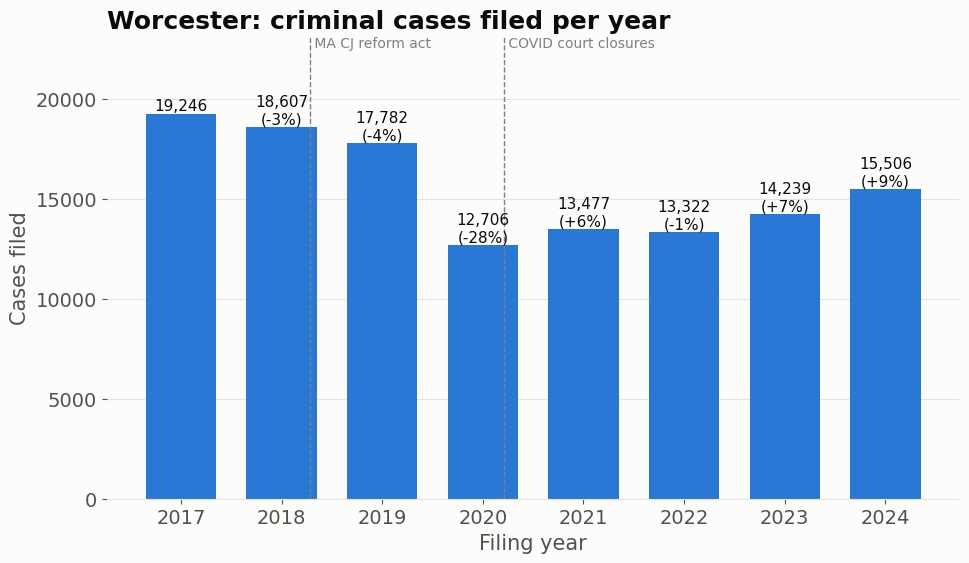

,cases,pct_change_yoy,pct_change_vs_2017
filing_year,,,
2017,19246,NaN,0.0
2018,18607,-3.3,-3.3
2019,17782,-4.4,-7.6
2020,12706,-28.5,-34.0
2021,13477,6.1,-30.0
2022,13322,-1.2,-30.8
2023,14239,6.9,-26.0
2024,15506,8.9,-19.4


In [42]:
plot_volume(vol, COUNTY, f"{FIG_DIR}/{COUNTY}_q1_volume.png")

**How this was calculated**
- **Unit:** cases (one `case_id` = one docket per defendant)
- **Source:** filed extract, so open cases are counted
- **Date field:** filing date (earliest charge in the case)
- **Filters:** filing years 2017 to 2024; motor vehicle offenses excluded

**Note:** The team doc cites a 32% drop in 2020 and 13% below 2017. These figures differ because motor vehicle offenses are excluded here and cases are counted per docket × defendant.

## 2. Per-Capita Rate
**Question:** How many cases are filed per 10,000 residents?
**Metric:** cases / annual county population × 10,000. Use annual ACS or PEP estimates, not a flat 2020 Census figure.

In [43]:
POPULATION = {  # annual county population estimates (Census PEP)
    2017: None, 2018: None, 2019: None, 2020: None,
    2021: None, 2022: None, 2023: None, 2024: None,
}
plot_per_capita(vol, POPULATION, COUNTY, f"{FIG_DIR}/{COUNTY}_q2_per_capita.png")

Q2: fill in annual population for every year to compute per-capita rates.


**How this was calculated**
- **Numerator:** cases filed per year (from Q1)
- **Denominator:** annual county population (source and vintage to be agreed by the team). Not computed until `POPULATION` is filled in.

## 3. Case Outcomes
**Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
**Metric:** % of disposed criminal cases by most severe outcome, overall and by year. CWOF is reported separately.

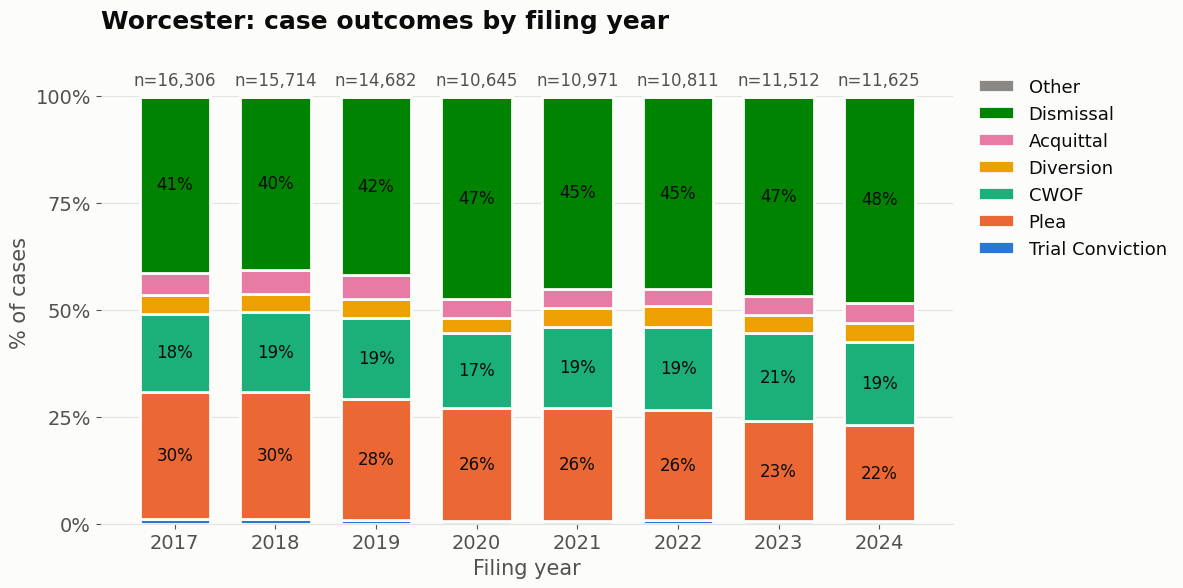

,cases,pct
outcome,,
Dismissal,44923,43.9
Plea,27456,26.8
CWOF,19312,18.9
Acquittal,5004,4.9
Diversion,4450,4.4
Trial Conviction,873,0.9
Other,248,0.2


outcome,Acquittal,CWOF,Dismissal,Diversion,Other,Plea,Trial Conviction
year,,,,,,,
2017,5.2,18.1,41.2,4.4,0.2,29.9,1.0
2018,5.6,18.6,40.3,4.3,0.4,29.7,1.1
2019,5.6,18.8,41.6,4.4,0.3,28.3,0.9
2020,4.3,17.4,47.2,3.7,0.3,26.3,0.7
2021,4.4,19.0,45.0,4.5,0.1,26.3,0.7
2022,4.1,19.5,44.9,4.7,0.2,25.7,0.9
2023,4.5,20.7,46.7,4.2,0.2,23.2,0.7
2024,4.8,19.3,48.1,4.5,0.2,22.5,0.6


In [44]:
overall, by_year_pct = plot_outcomes(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q3_outcomes_by_year.png")
display(overall, by_year_pct)

**How this was calculated**
- **Unit:** disposed criminal cases (one `case_id` per defendant), pending cases excluded
- **Outcome rule:** most severe outcome across the case's charges
- **Date field:** filing year
- **Mapping:** see `COUNTY_OUTCOMES` above. Dismissal = dismissed (with or without prejudice), nolle prosequi. Trial Conviction = jury or jury-waived trial guilty. Plea = guilty, guilty filed/fines, delinquent findings. CWOF = CWOF and plea CWOF. Diversion = pretrial probation, diversion and CATI program compliance, filed without plea/finding, Valor Act. Acquittal = not guilty at trial, directed verdict, required finding of not guilty, not criminally responsible. Civil infractions excluded.

**Note:** Cases filed in 2023 to 2024 that were still open at extraction are missing from the disposed extract, so recent years lean toward fast-resolving cases.

## 4. Sentencing
**Question:** What share of convictions result in incarceration, probation, or fines/other?
**Metric:** % of convicted cases (Trial Conviction or Plea) by most severe sentence type. The missing share is reported next to every rate.

Sentence text missing among convicted charges: 19.4%
Incarceration based only on a bare term (e.g. '6 MONTHS'): 8.8% of convicted charges
sentence_type
100          503
500          220
200          212
$100 FINE    206
50           137
250          119
150          102
1 YR          62
$200 FINE     60
SAME AS 1     55
G-FILE        47
$500 FINE     45
$50 FINE      45
300           43
G-$100        38
Name: count, dtype: int64
Missing sentence type: 14.2% of convicted cases


,cases,pct
sentence,,
Incarceration,11347,40.1
Probation,9382,33.1
Fines/Other,3571,12.6
Unknown,4029,14.2


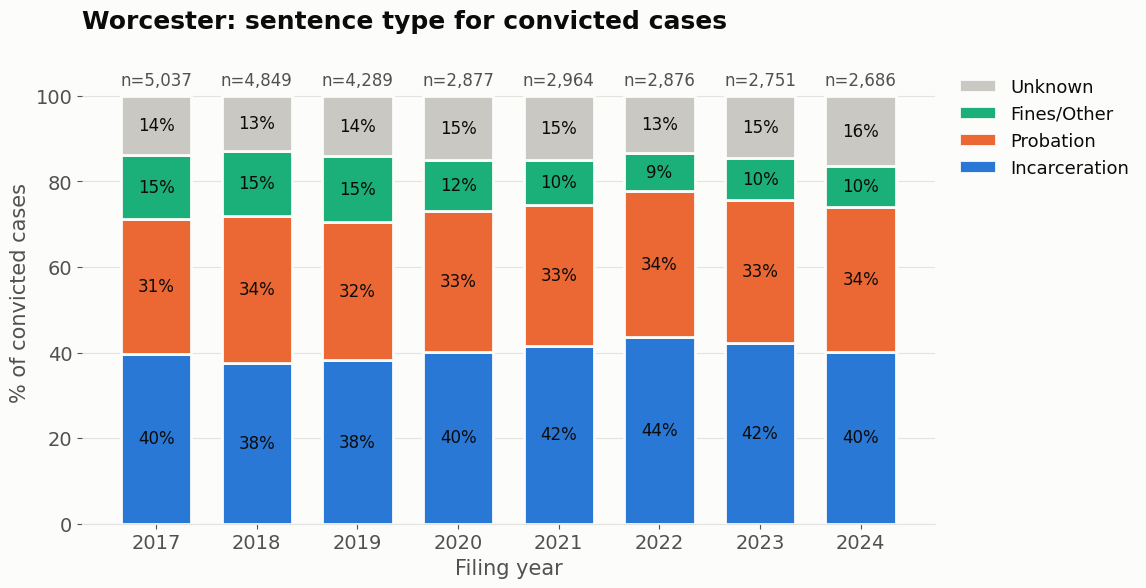

In [45]:
SENTENCE_RANK = ["Incarceration", "Probation", "Fines/Other", "Unknown"]
SENTENCE_COLORS = {"Incarceration": "#2a78d6", "Probation": "#eb6834",
                   "Fines/Other": "#1baf7a", "Unknown": "#c9c8c2"}

import re

def classify_sentence(text):
    """Worcester sentence_description is free text: mostly bare amounts ("100", "$50 CC")
    plus terms ("6 MONTHS"). Bare terms with no probation/suspended wording are treated
    as incarceration; check the printed share below."""
    if pd.isna(text) or str(text).strip() == "":
        return "Unknown"
    t = str(text).upper()
    if re.search(r"PROB|SUSP|\bSS\b", t):
        return "Probation"
    if re.search(r"JAIL|HOC|HOUSE OF CORR|PRISON|\bDOC\b|\bMCI\b|COMMIT|INCARC|TIME SERVED", t):
        return "Incarceration"
    if re.search(r"\b(DAY|DAYS|MONTH|MONTHS|MOS|YEAR|YEARS|YRS)\b", t):
        return "Incarceration"
    return "Fines/Other"

conv = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])
                & disposed["filing_year"].isin(YEARS)].copy()
conv_missing = conv["sentence_type"].isna().mean()
print(f"Sentence text missing among convicted charges: {conv_missing:.1%}")

if conv_missing > MISSING_THRESHOLD:
    print("Sentence type: insufficient data among convicted cases")
else:
    conv["sentence"] = conv["sentence_type"].map(classify_sentence)
    bare_term = conv["sentence_type"].astype(str).str.upper().str.contains(
        r"\b(?:DAY|DAYS|MONTH|MONTHS|MOS|YEAR|YEARS|YRS)\b", regex=True) & (conv["sentence"] == "Incarceration") & \
        ~conv["sentence_type"].astype(str).str.upper().str.contains(r"JAIL|HOC|HOUSE OF CORR|PRISON|\bDOC\b|\bMCI\b|COMMIT|INCARC|TIME SERVED", regex=True)
    print(f"Incarceration based only on a bare term (e.g. '6 MONTHS'): {bare_term.mean():.1%} of convicted charges")
    print(conv.loc[conv["sentence"] == "Fines/Other", "sentence_type"].value_counts().head(15))
    rank = {s: i for i, s in enumerate(SENTENCE_RANK)}
    case_sent = (conv.assign(r=conv["sentence"].map(rank))
                     .sort_values("r").groupby("case_key")
                     .agg(sentence=("sentence", "first"), filing_year=("filing_year", "first")))

    summary = case_sent["sentence"].value_counts().reindex(SENTENCE_RANK, fill_value=0).rename("cases").to_frame()
    summary["pct"] = (summary["cases"] / summary["cases"].sum() * 100).round(1)
    print(f"Missing sentence type: {summary.loc['Unknown', 'pct']}% of convicted cases")
    display(summary)

    by_year = case_sent.groupby("filing_year")["sentence"].value_counts().unstack(fill_value=0)
    by_year = by_year.reindex(columns=SENTENCE_RANK, fill_value=0)
    pct = by_year.div(by_year.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots()
    bottom = np.zeros(len(pct))
    for s in SENTENCE_RANK:
        ax.bar(pct.index, pct[s], bottom=bottom, color=SENTENCE_COLORS[s], label=s,
               width=0.7, edgecolor="#fcfcfb", linewidth=2)
        for x, v, b in zip(pct.index, pct[s], bottom):
            if v >= 6:
                ax.text(x, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=12)
        bottom += pct[s].values
    for x, n in zip(by_year.index, by_year.sum(axis=1)):
        ax.text(x, 101.5, f"n={n:,}", ha="center", va="bottom", fontsize=12, color=TEXT_SECONDARY)
    ax.set_ylim(0, 108); ax.set_xticks(list(pct.index))
    ax.set_ylabel("% of convicted cases"); ax.set_xlabel("Filing year")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{COUNTY.title()}: sentence type for convicted cases", pad=24)
    save_fig(fig, f"{FIG_DIR}/{COUNTY}_q4_sentencing.png")
    plt.show()

**How this was calculated**
- **Unit:** convicted cases (Trial Conviction or Plea; CWOF is not a conviction)
- **Sentence rule:** most severe sentence across the case's convicted charges (Incarceration > Probation > Fines/Other)
- **Parsing:** `sentence_description` free text. "PROB", "SUSP" = probation. "HOC", "JAIL", "DOC", "MCI", "COMMIT", "TIME SERVED" = incarceration. Bare amounts ("100", "$100 FINE") and other text = fines/other.
- **Assumption:** a bare term with no probation wording (e.g. "1 YR", "6 MONTHS") is treated as incarceration. The share of convicted charges relying on this is printed above; some may be probation terms.
- **Missing:** share of convicted cases with no sentence text is printed above (Unknown row). The structured `impsd_*` sentence fields are empty in this extract.

## 5. Pretrial Detention and Bail
**Question:** What share of defendants are held pretrial, and how often is cash bail set?
**Metric:** % released on personal recognizance, % with cash bail set, % held without bail, % of cash-bail cases unable to post, median bail amount.
Drop out-of-range bail dates before picking the first arraignment.

In [46]:
bail = read_any(BAIL_PATH)
print(bail["bail_status_description"].value_counts(dropna=False))
print(bail["hearing_type"].value_counts(dropna=False).head(10))

bail_status_description
Released PR No Conditions         49842
Released PR w Conditions          34160
In Custody, Bail Set              30512
No Status                         17029
Released on Cash Bail/Posted      10109
Held Without Bail                  9334
Dangerous, Held Without Bail       5140
Found Dangerous, Bail              2050
Dangerous, Released PR              792
Released on Surety                  285
In Custody, No Bail Set             260
Released but Ordered to Return       38
None                                 10
Name: count, dtype: int64
hearing_type
ARR    149237
DH      10324
Name: count, dtype: int64


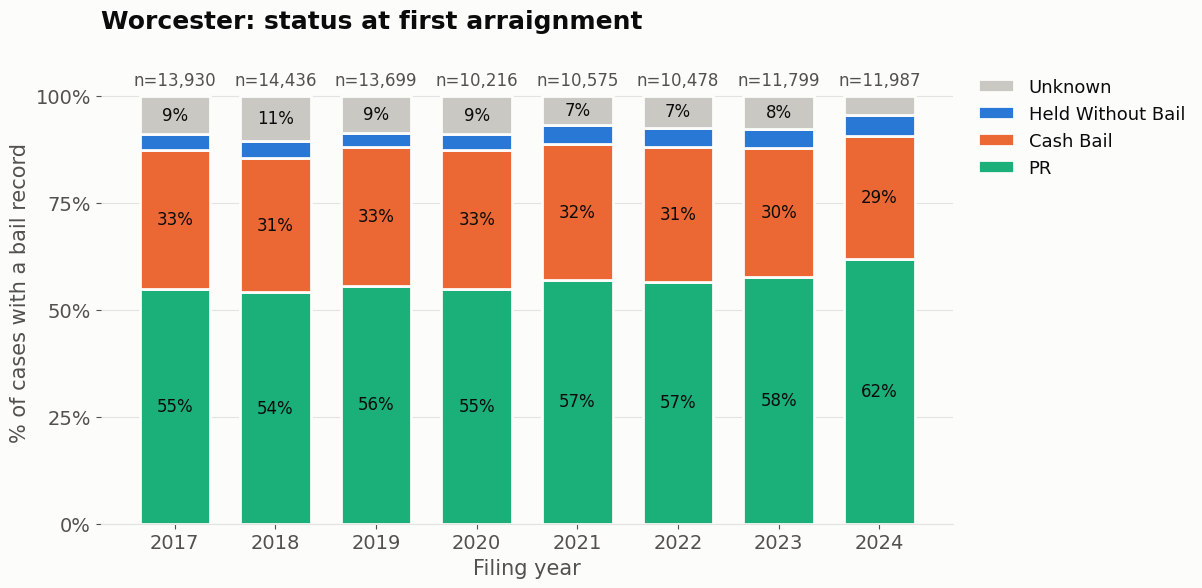

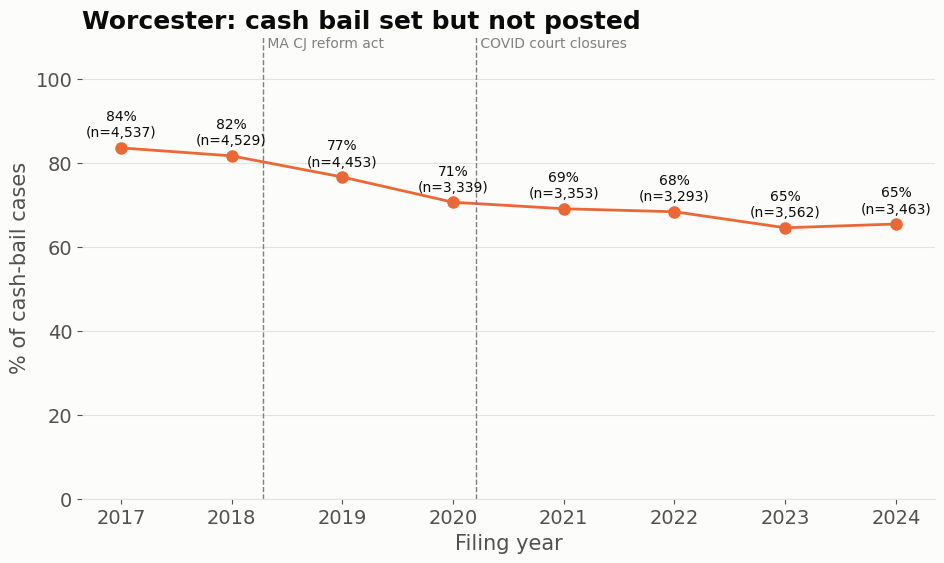

,value
bail record coverage (% of filed cases),77.8
% PR,56.5
% cash bail set,31.4
% held without bail,4.1
% no status (Unknown),8.0
% of cash-bail cases unable to post,73.3
median cash bail ($),500.0
median cash bail requested ($),1000.0


status,PR,Cash Bail,Held Without Bail,Unknown
year,,,,
2017,54.8,32.6,3.7,9.0
2018,54.1,31.4,4.0,10.5
2019,55.7,32.5,3.2,8.6
2020,54.8,32.7,3.6,8.9
2021,57.0,31.7,4.4,6.9
2022,56.6,31.4,4.6,7.4
2023,57.6,30.2,4.5,7.7
2024,61.9,28.9,4.8,4.5


In [47]:
# Map Worcester bail statuses onto shared groups
BAIL_STATUS_MAP = {
    "Released PR No Conditions": "PR",
    "Released PR w Conditions": "PR",
    "Dangerous, Released PR": "PR",
    "In Custody, Bail Set": "Cash Bail",
    "Released on Cash Bail/Posted": "Cash Bail",
    "Released on Surety": "Cash Bail",
    "Found Dangerous, Bail": "Cash Bail",
    "Held Without Bail": "Held Without Bail",
    "Dangerous, Held Without Bail": "Held Without Bail",
    "In Custody, No Bail Set": "Held Without Bail",
    "No Status": "Unknown",
}
NOT_POSTED = ["In Custody, Bail Set", "Found Dangerous, Bail"]   # bail set, defendant held

b = bail.copy()
b["bail_date"] = pd.to_datetime(b["bail_date"], errors="coerce")
b = b[b["bail_date"].dt.year.between(2017, 2024)]              # drop out-of-range dates
b = b[b["hearing_type"] == "ARR"]                               # arraignments only

# Bail file has case_id only; attach the shared case_key
key_lookup = filed.drop_duplicates("docket_number").set_index("docket_number")["case_key"]
b["case_key"] = b["case_id"].map(key_lookup)
b = b[b["case_key"].isin(filed_cases["case_key"])]

first = b.sort_values("bail_date").groupby("case_key").first()  # first arraignment per case

# Standardized bail table -> shared Q5 charts
fy = filed_cases.set_index("case_key")["filing_year"]
bail_std = pd.DataFrame({
    "case_key": first.index,
    "year": first.index.map(fy).astype(int),
    "status": first["bail_status_description"].map(BAIL_STATUS_MAP).fillna("Unknown").values,
    "unable_to_post": first["bail_status_description"].isin(NOT_POSTED).values,
    "amount": first["bail_amount_set"].values,
})
q5_table, q5_by_year = plot_bail(bail_std, COUNTY, f"{FIG_DIR}/{COUNTY}_q5_bail_status.png",
                                 post_path=f"{FIG_DIR}/{COUNTY}_q5_unable_to_post.png",
                                 n_filed=len(filed_cases))

# Worcester extra: requested amount (not in the shared table)
cash = first[bail_std.set_index("case_key")["status"].reindex(first.index).eq("Cash Bail")]
q5_table.loc["median cash bail requested ($)"] = round(
    pd.to_numeric(cash["bail_amount_requested"], errors="coerce").median(), 1)
display(q5_table, q5_by_year)

**How this was calculated**
- **Unit:** cases with a bail record; first arraignment (hearing type ARR) per case
- **Join:** bail `case_id` matched to the case table
- **Status groups:** PR = released on personal recognizance (with or without conditions). Cash bail = bail set (posted, surety, or still in custody). Held without bail = held without bail, including after a dangerousness finding.
- **Unable to post:** cash-bail cases with status "In Custody, Bail Set" or "Found Dangerous, Bail" at the first arraignment
- **Coverage:** share of filed cases with a bail record (first row of the table above)
- **Charts:** status at first arraignment by filing year; share of cash-bail cases unable to post by filing year (years under 30 cases hidden)
- **Filters:** bail dates outside 2017 to 2024 dropped

## 6. Time to Disposition
**Question:** What is the median time from filing to disposition, and does it differ by case type?
**Metric:** median and IQR of days, by offense category and court. Pending cases and negative intervals are excluded.

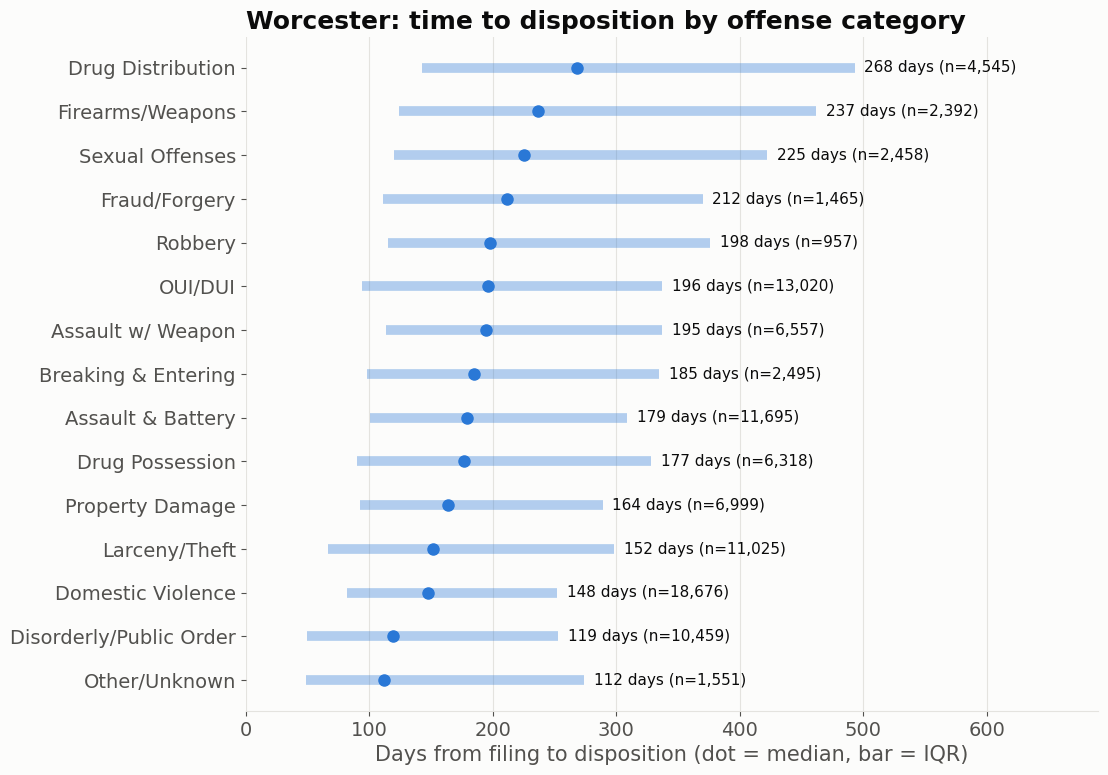

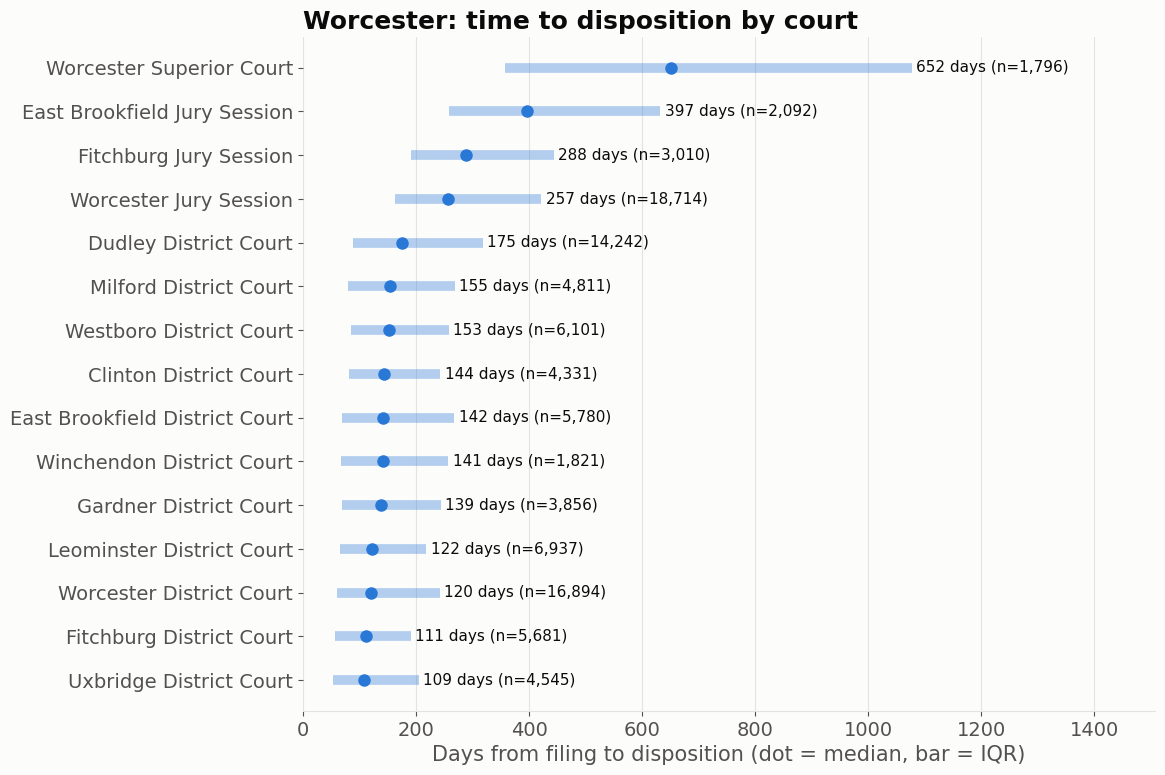

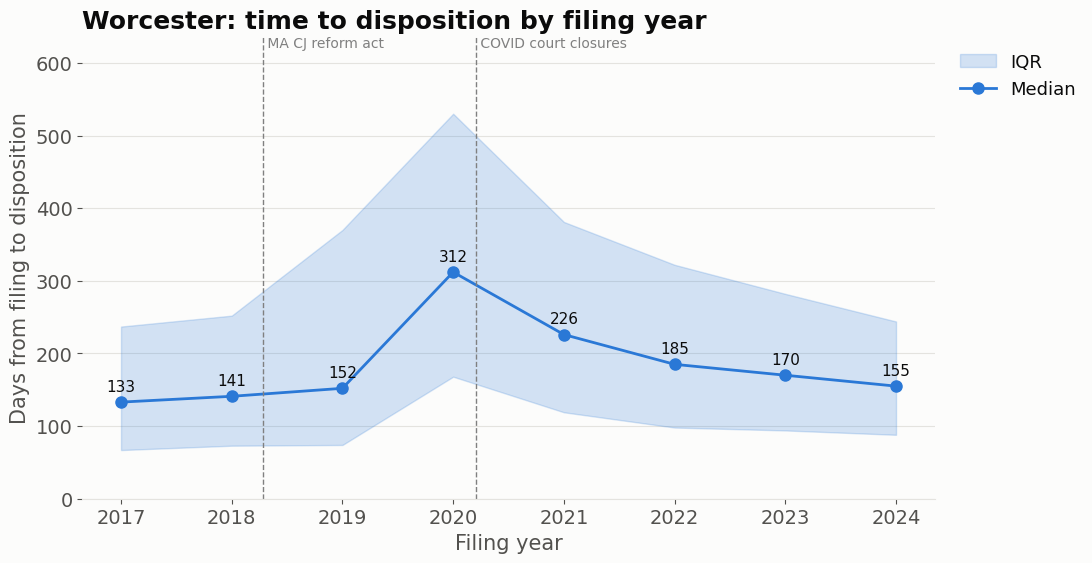

Overall median: 170 days (IQR 87-312)


,n,median,q1,q3
offense,,,,
Assault & Battery,11695,179.0,101.0,309.0
Assault w/ Weapon,6557,195.0,114.0,337.0
Breaking & Entering,2495,185.0,98.0,335.0
Disorderly/Public Order,10459,119.0,50.0,253.0
Domestic Violence,18676,148.0,82.0,252.0
Drug Distribution,4545,268.0,143.0,493.0
Drug Possession,6318,177.0,90.0,328.0
Firearms/Weapons,2392,237.0,124.0,462.0
Fraud/Forgery,1465,212.0,111.0,370.0


,n,median,q1,q3
court,,,,
Clinton District Court,4331,144.0,81.0,243.0
Dudley District Court,14242,175.0,89.0,318.0
East Brookfield District Court,5780,142.0,69.0,268.0
East Brookfield Jury Session,2092,397.0,258.0,632.0
Fitchburg District Court,5681,111.0,56.0,191.0
Fitchburg Jury Session,3010,288.0,192.0,444.0
Gardner District Court,3856,139.0,69.0,244.0
Leominster District Court,6937,122.0,65.0,218.0
Milford District Court,4811,155.0,79.0,269.0


,n,median,q1,q3
year,,,,
2017,16002,133.0,67.0,237.0
2018,15479,141.0,73.0,252.0
2019,14451,152.0,74.0,370.0
2020,10529,312.0,168.0,530.0
2021,10752,226.0,119.0,381.0
2022,10615,185.0,98.0,322.0
2023,11380,170.0,94.0,282.0
2024,11404,155.0,88.0,244.0


In [48]:
t6_offense = plot_time(std, "offense", "offense category", COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_offense.png")
t6_court = plot_time(std, "court", "court", COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_court.png")
t6_year = plot_time_by_year(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_year.png")
print(f"Overall median: {std['days'].median():.0f} days "
      f"(IQR {std['days'].quantile(.25):.0f}-{std['days'].quantile(.75):.0f})")
display(t6_offense, t6_court, t6_year)

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** earliest filing date to latest disposition date in the case; negative intervals excluded
- **Charts:** by offense category, by court, and by filing year (dot or line = median, bar or band = IQR)
- **Filters:** groups with fewer than 30 cases hidden

**Note:** pending cases are excluded, so 2023-24 medians are biased low.

## 7. Disparities by Race and Sex
**Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
**Metric:** rate per group, plus rate ratios vs. White and vs. Male. Unknown race is kept as its own group. Groups under 30 cases are suppressed.

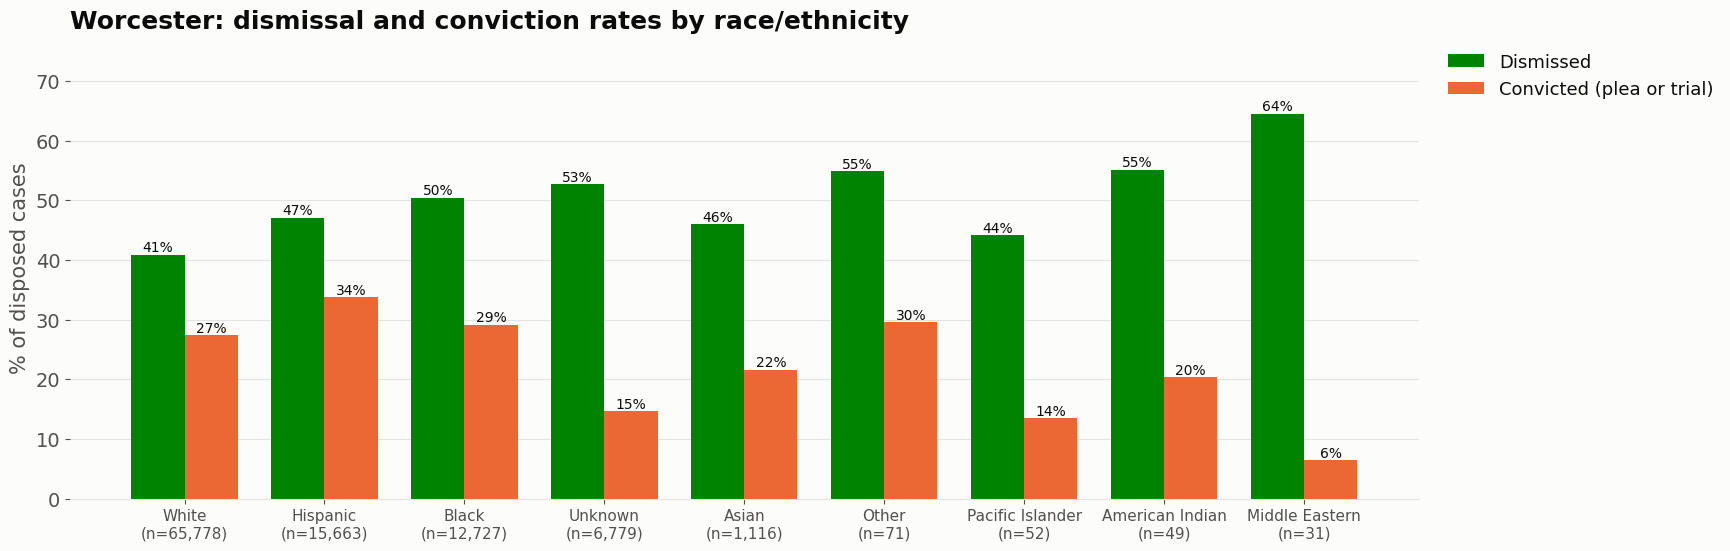

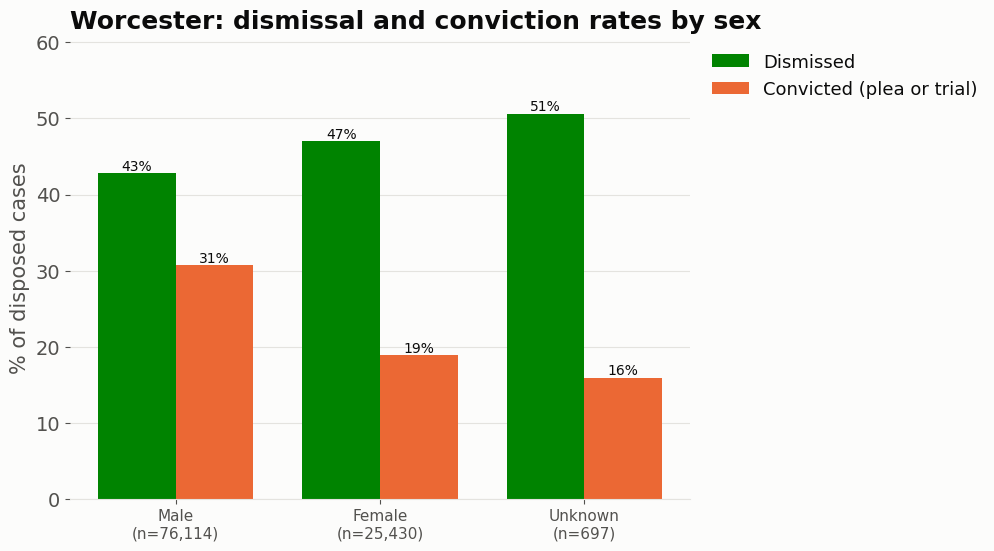

,n,dismissal_pct,dismissal_ratio_vs_White,conviction_pct,conviction_ratio_vs_White
race,,,,,
White,65778,40.9,1.00,27.4,1.00
Hispanic,15663,47.1,1.15,33.8,1.23
Black,12727,50.4,1.23,29.2,1.07
Unknown,6779,52.7,1.29,14.7,0.54
Asian,1116,46.0,1.12,21.6,0.79
Other,71,54.9,1.34,29.6,1.08
Pacific Islander,52,44.2,1.08,13.5,0.49
American Indian,49,55.1,1.35,20.4,0.74
Middle Eastern,31,64.5,1.58,6.5,0.24


,n,dismissal_pct,dismissal_ratio_vs_Male,conviction_pct,conviction_ratio_vs_Male
sex,,,,,
Male,76114,42.8,1.00,30.7,1.00
Female,25430,47.0,1.10,18.9,0.62
Unknown,697,50.6,1.18,15.9,0.52



Incarceration rate (convicted cases) by race [Worcester only]


,n,incarceration_pct,ratio_vs_White
race,,,
Asian,241,35.7,0.95
Black,3721,45.6,1.22
Hispanic,5293,45.8,1.22
Unknown,999,36.6,0.98
White,18035,37.5,1.00



Incarceration rate (convicted cases) by sex [Worcester only]


,n,incarceration_pct,ratio_vs_Male
sex,,,
Female,4816,32.2,0.77
Male,23399,41.7,1.00
Unknown,111,36.9,0.89


In [49]:
t7_race = plot_rates(std, "race", "White", "race/ethnicity", COUNTY, f"{FIG_DIR}/{COUNTY}_q7_rates_by_race.png")
t7_sex = plot_rates(std, "sex", "Male", "sex", COUNTY, f"{FIG_DIR}/{COUNTY}_q7_rates_by_sex.png")
display(t7_race, t7_sex)

# Worcester only: incarceration among convicted cases (other counties lack sentence data)
if "case_sent" in globals():
    inc = case_sent.join(cases.set_index("case_key")[["race", "sex"]], how="inner")
    inc["incarcerated"] = inc["sentence"].eq("Incarceration")
    for group, ref in [("race", "White"), ("sex", "Male")]:
        g = inc.groupby(group)["incarcerated"].agg(n="size", rate="mean")
        g = g[g["n"] >= MIN_CELL]
        g["incarceration_pct"] = (g["rate"] * 100).round(1)
        g[f"ratio_vs_{ref}"] = (g["rate"] / g.loc[ref, "rate"]).round(2)
        print(f"\nIncarceration rate (convicted cases) by {group} [Worcester only]")
        display(g.drop(columns="rate"))

**How this was calculated**
- **Unit:** disposed cases
- **Rates:** dismissal = Dismissal bucket; conviction = Plea or Trial Conviction (same in every county)
- **Rate ratio:** group rate / reference group rate (White for race, Male for sex)
- **Filters:** groups under 30 cases suppressed; Unknown kept as its own group
- **Worcester only:** incarceration rate among convicted cases (table above); other counties lack sentence data

**Note:** Declination (cases the prosecutor declined to file) is not measurable in this extract.

## 8. Disparities with Controls
**Question:** Do racial gaps remain within the same offense category and prior-record level?
**Metric:** dismissal rate by race within offense category × prior-record cells. Cells under 30 cases are suppressed.

**Prior record:** number of earlier cases for the same defendant filed in the **3 years** before this case (same lookback in every county), bucketed 0 / 1-2 / 3+.

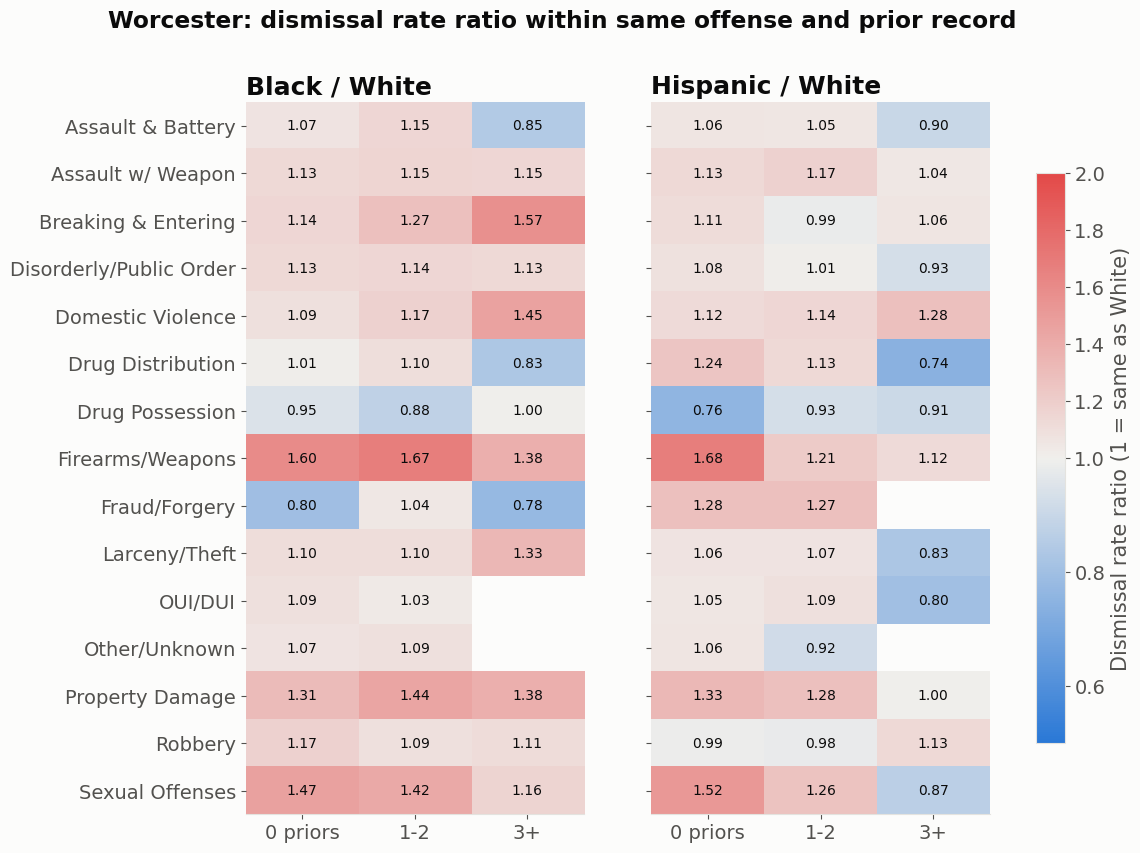

Q8 cases with known prior record: 102,266


race                                  Asian  Black  Hispanic  Unknown  White
offense                 prior_record                                        
Assault & Battery       0              59.1   60.2      59.8     60.8   56.4
                        1-2            40.5   55.8      51.1     49.4   48.6
                        3+              NaN   38.4      40.8      NaN   45.4
Assault w/ Weapon       0              68.4   66.6      66.9     67.3   59.1
                        1-2             NaN   57.4      58.5     60.4   49.9
                        3+              NaN   57.5      52.1      NaN   50.1
Breaking & Entering     0               NaN   40.3      39.3     52.0   35.3
                        1-2             NaN   41.3      32.0      NaN   32.4
                        3+              NaN   53.0      35.9      NaN   33.8
Disorderly/Public Order 0              64.9   60.2      57.5     64.4   53.3
                        1-2             NaN   50.2      44.5     61.3   44.0
                        3+              NaN   39.5      32.5     42.9   34.9
Domestic Violence       0              76.4   70.8      72.9     71.6   64.9
                        1-2            51.4   62.8      61.1     53.5   53.5
                        3+              NaN   63.8      56.0     60.5   43.9
Drug Distribution       0              34.4   44.3      54.3     52.1   43.7
                        1-2             NaN   35.0      35.8     33.3   31.8
                        3+              NaN   26.4      23.6      NaN   31.7
Drug Possession         0              24.2   30.6      24.6     48.8   32.3
                        1-2             NaN   23.8      25.2     42.9   27.1
                        3+              NaN   24.5      22.2      NaN   24.4
Firearms/Weapons        0               NaN   46.9      49.2     37.3   29.3
                        1-2             NaN   56.9      41.2      NaN   34.0
                        3+              NaN   50.7      41.3      NaN   36.8
Fraud/Forgery           0               NaN   37.2      59.3     40.5   46.5
                        1-2             NaN   32.8      40.0      NaN   31.4
                        3+              NaN   22.6       NaN      NaN   29.1
Larceny/Theft           0              45.1   47.1      45.4     54.7   42.7
                        1-2             NaN   33.4      32.3     53.1   30.3
                        3+              NaN   27.5      17.2     56.1   20.7
OUI/DUI                 0               7.8   10.9      10.5     11.3   10.0
                        1-2             NaN   15.8      16.7     13.6   15.3
                        3+              NaN    NaN      16.1      NaN   20.1
Other/Unknown           0               NaN   84.7      84.4     87.8   79.5
                        1-2             NaN   79.4      67.2      NaN   73.0
                        3+              NaN    NaN       NaN      NaN   51.8
Property Damage         0              38.6   54.3      54.9     47.5   41.4
                        1-2             NaN   56.2      49.8     50.0   38.9
                        3+              NaN   46.7      33.9      NaN   33.8
Robbery                 0               NaN   76.6      64.6     69.4   65.2
                        1-2             NaN   65.3      59.1      NaN   60.1
                        3+              NaN   57.1      57.8      NaN   51.3
Sexual Offenses         0              67.3   57.0      59.2     42.3   38.9
                        1-2             NaN   49.4      43.9      NaN   34.9
                        3+              NaN   33.3      25.0      NaN   28.7

In [50]:
if "defendant_id" in INSUFFICIENT:
    print("Q8: insufficient data (defendant ID over 20% missing)")
else:
    q8_rates = plot_q8_heatmap(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q8_dismissal_ratio_heatmap.png")
    display(q8_rates)

**How this was calculated**
- **Unit:** disposed cases with a known prior record
- **Prior record:** the defendant's cases filed in the 3 years before this case (same lookback in every county), bucketed 0 / 1-2 / 3+
- **Cells:** offense category × prior record × race; cells under 30 cases suppressed
- **Heatmap value:** group dismissal rate / White dismissal rate in the same cell (1.00 = no gap; blue = lower, red = higher)

**Limitation:** prior record only counts cases in this county's extract, not statewide history.

## Cross-County Comparison View (District Courts Only)
Plymouth's Superior Court records stop after 2020, so the Plymouth analysis covers district courts only. This view restricts Worcester to district courts (District Court and Jury Session; Superior Court excluded) so the two counties can be compared on the same court scope.

Use these numbers on any slide that compares counties. The full-county results above remain the main Worcester answers.

District-only: 100,460 disposed cases (98.2% of all)


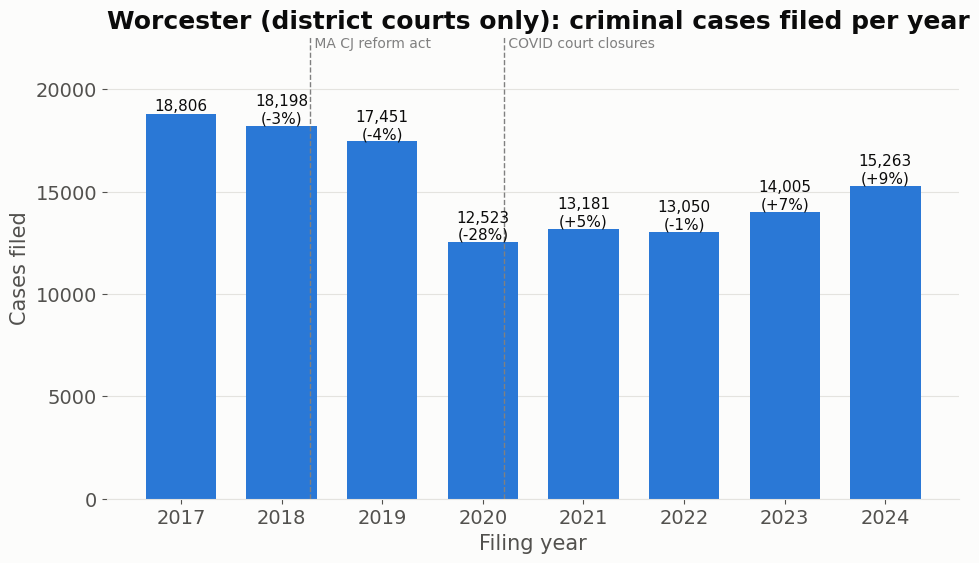

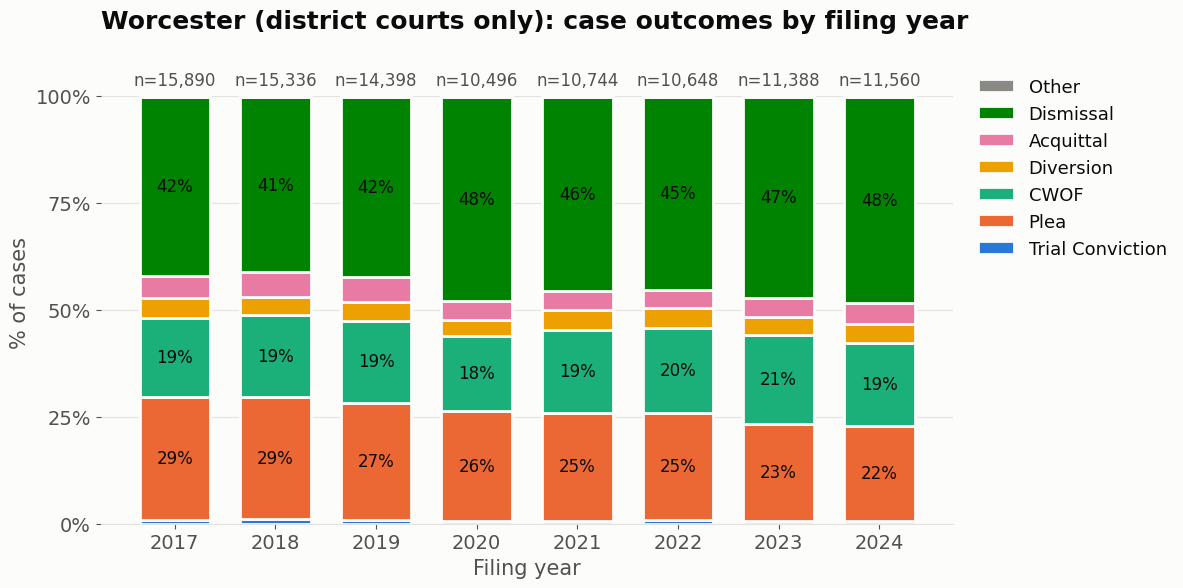

,cases,pct
outcome,,
Dismissal,44619,44.4
Plea,26092,26.0
CWOF,19295,19.2
Acquittal,4936,4.9
Diversion,4449,4.4
Trial Conviction,827,0.8
Other,242,0.2


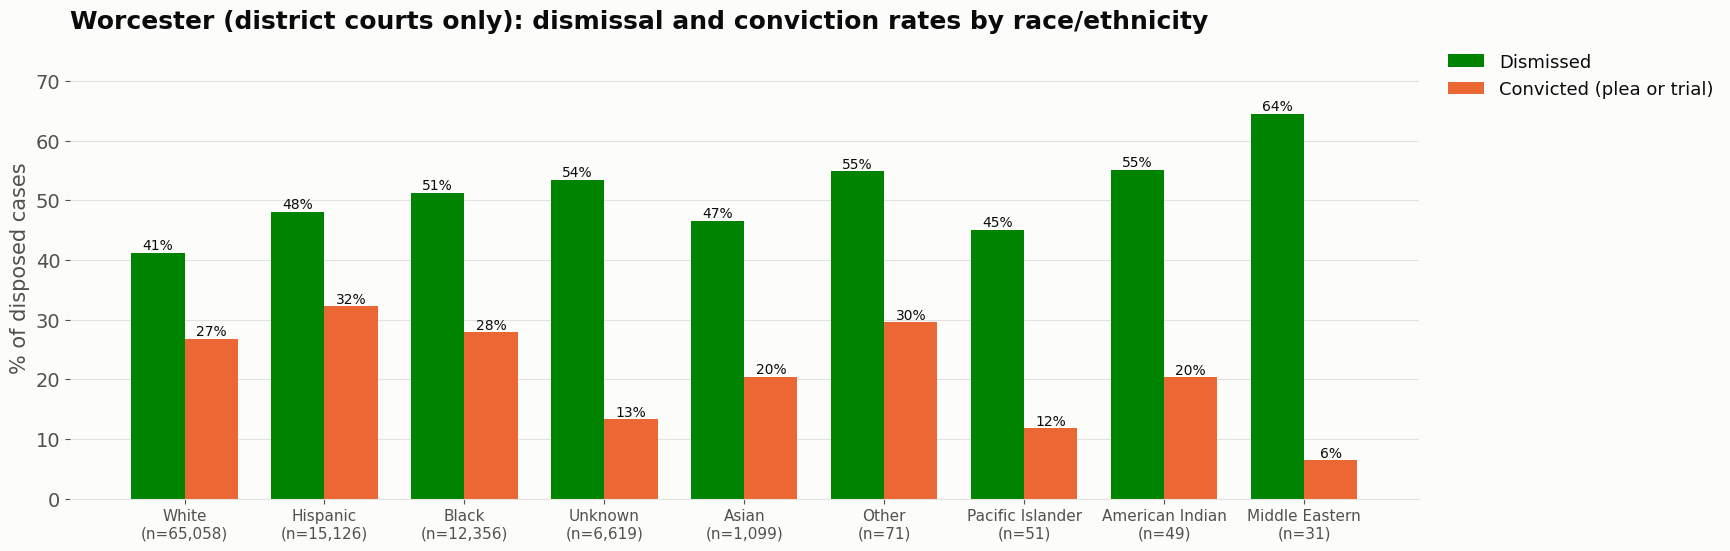

,n,dismissal_pct,dismissal_ratio_vs_White,conviction_pct,conviction_ratio_vs_White
race,,,,,
White,65058,41.2,1.00,26.8,1.00
Hispanic,15126,48.1,1.17,32.3,1.20
Black,12356,51.3,1.24,27.9,1.04
Unknown,6619,53.5,1.30,13.3,0.50
Asian,1099,46.6,1.13,20.5,0.76
Other,71,54.9,1.33,29.6,1.10
Pacific Islander,51,45.1,1.09,11.8,0.44
American Indian,49,55.1,1.34,20.4,0.76
Middle Eastern,31,64.5,1.56,6.5,0.24


In [51]:
std_d = std[~std["court"].astype(str).str.contains("Superior", case=False)]
vol_d = filed_cases[~filed_cases["court"].astype(str).str.contains("Superior", case=False)] \
            .groupby("filing_year").size()
vol_d.index = vol_d.index.astype(int)
print(f"District-only: {len(std_d):,} disposed cases ({len(std_d) / len(std):.1%} of all)")

scope = "district courts only"
plot_volume(vol_d, COUNTY, f"{FIG_DIR}/{COUNTY}_compare_q1_volume_district.png", scope=scope)
overall_d, _ = plot_outcomes(std_d, COUNTY, f"{FIG_DIR}/{COUNTY}_compare_q3_outcomes_district.png", scope=scope)
display(overall_d)
display(plot_rates(std_d, "race", "White", "race/ethnicity", COUNTY,
                   f"{FIG_DIR}/{COUNTY}_compare_q7_rates_by_race_district.png", scope=scope))

**How this was calculated**
- Same definitions as the sections above, restricted to cases whose lead charge was heard in a District Court or Jury Session
- Superior Court cases are excluded to match Plymouth's court coverage

## Questions for the Client
- Are the structured sentence fields (`impsd_*`) available? They are empty in this extract, so sentence type is parsed from free text.
- Is a statewide prior-record field available? Prior record here only counts Worcester cases.
- Can declined referrals be provided? Declination isn't measurable in this extract.